The (published) kinematic model ODEs are
\begin{align*}
    \frac{dr_1}{dt} & = k_1r_t + 2k_2^-r_2 - 2k_2^+r_1^2 - (\lambda_1 + \lambda_c)r_1 \\
    \frac{dr_2}{dt} & = k_2^+r_1^2 + k_3^-r_3 - 2k_3^+r_2S - (k_2^- + \lambda_2 + \lambda_c)r_2 \\
    \frac{dr_3}{dt} & = 2k_3^+r_2S + 2k_4^-r_4 - k_4^+r_3S - (k_3^- + \lambda_3 + \lambda_c)r_3 \\
    \frac{dr_4}{dt} & = k_4^+r_3S - (2k_4^- + \lambda_4 + \lambda_c)r_4 \\
    \frac{ds_a}{dt} & = k_s^+r_4(s_t - s_a) - (k_s^- + \lambda_c)s_a \\
    \frac{dn}{dt} & = b_ns_t + (k_n - b_n)s_a - (k_g + \lambda_n + \lambda_c)n \\
    \frac{dg}{dt} & = k_gn - (\lambda_g + \lambda_c)g.
\end{align*}

In [2]:
import numpy as np

def kinetic_ODEs(t, x, signal_fun, pars):
    lambda_1, lambda_2, lambda_3, lambda_4, lambda_n, lambda_g, lambda_c = pars['lambda_dictionary'].values()
    k_1, k_2_p, k_2_m, k_3_p, k_3_m, k_4_p, k_4_m, k_s_p, k_s_m, k_n, k_g = pars['k_dictionary'].values()
    b_n = pars['b_n']
    r_t = pars['r_t']
    s_t = pars['s_t']

    r_1, r_2, r_3, r_4, s_a, n, g = x

    S = signal_fun(t)

    dr1_dt = k_1*r_t + 2*k_2_m*r_2 - 2*k_2_p*(r_1**2) - (lambda_1 + lambda_c)*r_1
    dr2_dt = k_2_p*(r_1**2) + k_3_m*r_3 - 2*k_3_p*r_2*S - (k_2_m + lambda_2 + lambda_c)*r_2
    dr3_dt = 2*k_3_p*r_2*S + 2*k_4_m*r_4 - k_4_p*r_3*S - (k_3_m + lambda_3 + lambda_c)*r_3
    dr4_dt = k_4_p*r_3*S - (2*k_4_m + lambda_4 + lambda_c)*r_4
    ds_a_dt = k_s_p*r_4*(s_t - s_a) - (k_s_m + lambda_c)*s_a
    dn_dt = b_n*s_t + (k_n - b_n)*s_a - (k_g + lambda_n + lambda_c)*n
    dg_dt = k_g*n - (lambda_g + lambda_c)*g

    return np.array([dr1_dt, dr2_dt, dr3_dt, dr4_dt, ds_a_dt, dn_dt, dg_dt])

'''Autonomous version of the ODEs with S(t) constant for faster computations.'''
def kinetic_ODEs_autonomous(t, x, S, pars):
    lambda_1, lambda_2, lambda_3, lambda_4, lambda_n, lambda_g, lambda_c = pars['lambda_dictionary'].values()
    k_1, k_2_p, k_2_m, k_3_p, k_3_m, k_4_p, k_4_m, k_s_p, k_s_m, k_n, k_g = pars['k_dictionary'].values()
    b_n = pars['b_n']
    r_t = pars['r_t']
    s_t = pars['s_t']

    r_1, r_2, r_3, r_4, s_a, n, g = x

    dr1_dt = k_1*r_t + 2*k_2_m*r_2 - 2*k_2_p*(r_1**2) - (lambda_1 + lambda_c)*r_1
    dr2_dt = k_2_p*(r_1**2) + k_3_m*r_3 - 2*k_3_p*r_2*S - (k_2_m + lambda_2 + lambda_c)*r_2
    dr3_dt = 2*k_3_p*r_2*S + 2*k_4_m*r_4 - k_4_p*r_3*S - (k_3_m + lambda_3 + lambda_c)*r_3
    dr4_dt = k_4_p*r_3*S - (2*k_4_m + lambda_4 + lambda_c)*r_4
    ds_a_dt = k_s_p*r_4*(s_t - s_a) - (k_s_m + lambda_c)*s_a
    dn_dt = b_n*s_t + (k_n - b_n)*s_a - (k_g + lambda_n + lambda_c)*n
    dg_dt = k_g*n - (lambda_g + lambda_c)*g

    return np.array([dr1_dt, dr2_dt, dr3_dt, dr4_dt, ds_a_dt, dn_dt, dg_dt])

In [3]:
t_d = 3 # Average cell cycle duration (hours); 3 is fast-growing.
lambda_c = np.log(2) / t_d # cell-cycle dependent protein degradation rate
lambda_d = 0.113 # lasR dimer degradation rate
lambda_gfp = 0.107

a = 349.30
lasR_production_rate = a + ((1000 - a)/0.231)*lambda_c # cell-cycle dependent protein production, used for k_1 and k_n
k_d_off = 3758 # off rates for lasR dimers, k_2-, k_3-, k_4-
k_d_on = 235.019 # on rates for lasR dimers with signals bound, k_3+, k_4+

K_s = 1.229 # complex DNA dissociation constant
k_s_m = 0.044
k_s_p = k_s_m / K_s

lambda_dictionary = {
    'lambda_1': 8.975,
    'lambda_2': lambda_d,
    'lambda_3': lambda_d,
    'lambda_4': lambda_d,
    'lambda_n': lambda_gfp,
    'lambda_g': lambda_gfp,
    'lambda_c': lambda_c,
}

k_dictionary = {
    'k_1': lasR_production_rate,
    'k_2_p': 1.490,
    'k_2_m': k_d_off, 
    'k_3_p': k_d_on, 
    'k_3_m': k_d_off, 
    'k_4_p': k_d_on, 
    'k_4_m': k_d_off, 
    'k_s_p': k_s_p, 
    'k_s_m': k_s_m, 
    'k_n': lasR_production_rate, 
    'k_g': 7.709,
}

pars = {
    'lambda_dictionary': lambda_dictionary,
    'k_dictionary': k_dictionary,
    'b_n': 0, # baseline production of gfp protein
    'r_t': 1, # genomic lasR concentration
    's_t': 8.986, # copy count of signal production genes
    'I_0': 5, # initial intensity in experiment (not given in paper)
    'A': 0.002,
}

def gfp_to_luminescence(gfp_time_series):
    return pars['I_0'] + pars['A']*gfp_time_series

def get_zero_signal_equilibrium(pars):
    r_t = pars['r_t']
    k_1 = pars['k_dictionary']['k_1']
    k_2_p = pars['k_dictionary']['k_2_p']
    k_2_m = pars['k_dictionary']['k_2_m']
    lambda_1 = pars['lambda_dictionary']['lambda_1']
    lambda_2 = pars['lambda_dictionary']['lambda_2']
    lambda_c = pars['lambda_dictionary']['lambda_c']

    ''' When there is no signal, solve dr_1/dt = 0 and dr_2/dt = 0 with all other components zero '''
    a = 2*k_2_p*( k_2_m / (k_2_m + lambda_2 + lambda_c) - 1)
    b = -(lambda_1 + lambda_c)
    c = k_1*r_t

    r_1 = (-b - np.sqrt(b**2 - 4*a*c)) / (2*a)
    r_2 = k_2_p*r_1**2 / (k_2_m + lambda_c + lambda_2)
    return [r_1, r_2, 0, 0, 0, 0, 0]

In [4]:
from scipy.integrate import solve_ivp

def s_fun(t):
    return 10 if t <= 6 else 0
    #return 0

odefun = lambda t, x: kinetic_ODEs(t, x, s_fun, pars)

init_cond = get_zero_signal_equilibrium(pars)
init_cond = [0, 0, 0, 0, 0, 0, 0]

sol = solve_ivp(odefun, t_span=[0,20], y0=init_cond)

(0.0, 80.0)

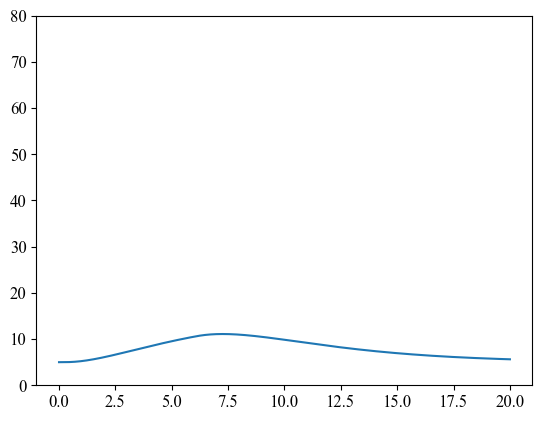

In [21]:
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 12
plt.rcParams['figure.dpi'] = 100

luminescene_time_series = gfp_to_luminescence(sol.y[-1])

plt.plot(sol.t, luminescene_time_series)
plt.ylim([0,80])

C:\Users\daths\AppData\Local\Temp\ipykernel_19032\2465742952.py:14: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


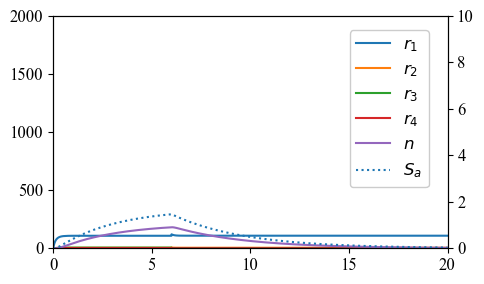

In [23]:
time_series_labels = [r'$r_1$', r'$r_2$', r'$r_3$', r'$r_4$', r'$S_a$', r'$n$']

fig, ax1 = plt.subplots(1, 1, figsize=(5,3), layout='constrained')
[ax1.plot(sol.t, sol.y[i], label=time_series_labels[i]) for i in [0, 1, 2, 3, 5]]

ax2 = ax1.twinx()
[ax2.plot(sol.t, sol.y[i], label=time_series_labels[i], linestyle=':') for i in [4]]
fig.legend(bbox_to_anchor=(0.89, 0.9), framealpha=1)

ax1.set_xlim([0,20])
ax1.set_ylim([0,2000])
ax2.set_ylim([0,10])

fig.tight_layout()

Comparing the equilibrium expression of the ODE model versus the hill function

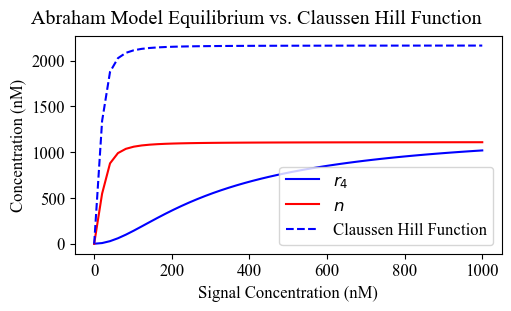

In [42]:
from scipy.optimize import root

def get_eq_location(pars, S):
    odefun = lambda x: kinetic_ODEs_autonomous(0, x, S, pars)
    found_equilibrium = False
    found_root = False
    feasible_root = False

    while found_equilibrium == False:
        found_root = feasible_root = False
        x0 = np.random.rand(7) * 10
        sol = root(odefun, x0)
        found_root = sol.success
        if found_root: feasible_root = np.all(sol.x >= 0)
        if feasible_root: found_equilibrium = True
    return sol.x

S_values = np.linspace(0, 1000, 50, endpoint=True)
eq_locations = np.array([get_eq_location(pars, S) for S in S_values])
r_4_equilibrium_values = eq_locations[:, 3]

def hill_function(S, alpha, K):
    return alpha * (np.pow(S,2)) / (K**2 + np.pow(S,2))

K_3 = pars['k_dictionary']['k_3_m'] / pars['k_dictionary']['k_3_p']
K_4 = pars['k_dictionary']['k_4_m'] / pars['k_dictionary']['k_4_p']
K_d = np.sqrt(K_3*K_4) # bad fit :(
K_d_good_fit = 450 # good fit
r_d = pars['k_dictionary']['k_1'] * pars['r_t'] / (2*pars['lambda_dictionary']['lambda_c'])

fig, ax1 = plt.subplots(1, 1, figsize=(5,3), layout='constrained')

ax1.plot(S_values, r_4_equilibrium_values, label=r'$r_4$', color='b')
ax1.plot(S_values, eq_locations[:, 5], label=r'$n$', color='r')
ax1.plot(S_values, hill_function(S_values, r_d, K_d), linestyle='--', label='Claussen Hill Function', color='b')
ax1.legend()

fig.suptitle('Abraham Model Equilibrium vs. Claussen Hill Function')
ax1.set_xlabel('Signal Concentration (nM)')
ax1.set_ylabel('Concentration (nM)')
plt.savefig('Figures/las_kinetic_model_equilibrium_vs_Claussen_hill_function.png', bbox_inches='tight')